In [2]:
from models_style_steering import (
    collect_harmony_layer_states,
    tokenwise_knn_accuracy,
)
from generate_utils import load_SELaC, nucleus_token_by_token_generate, generate_files_with_nucleus
from train_utils import full_to_partial_masking
import torch
from torch.utils.data import DataLoader, ConcatDataset
import numpy as np
import pickle
from tqdm import tqdm
from GridMLM_tokenizers import CSGridMLMTokenizer
from data_utils import CSGridMLMDataset, CSGridMLM_collate_fn
import matplotlib.pyplot as plt
from copy import deepcopy
import os
from dotenv import load_dotenv

/home/maximos/miniconda3/envs/torch/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
tokenizer = CSGridMLMTokenizer(
    fixed_length=80,
    quantization='4th',
    intertwine_bar_info=True,
    trim_start=False,
    use_pc_roll=True,
    use_full_range_melody=False
)

mask_token_id = tokenizer.mask_token_id
bar_token_id = tokenizer.bar_token_id

batchsize = 8

In [4]:
train_gjt = os.getenv('TRAIN_GJT')
train_nott = os.getenv('TRAIN_NOTT')

val_gjt = os.getenv('VAL_GJT')
val_nott = os.getenv('VAL_NOTT')

In [5]:
train_dataset_gjt = CSGridMLMDataset(train_gjt, tokenizer, frontloading=True, name_suffix='Q4_L80_bar_PC')
train_dataset_nott = CSGridMLMDataset(train_nott, tokenizer, frontloading=True, name_suffix='Q4_L80_bar_PC')

val_dataset_gjt = CSGridMLMDataset(val_gjt, tokenizer, frontloading=True, name_suffix='Q4_L80_bar_PC')
val_dataset_nott = CSGridMLMDataset(val_nott, tokenizer, frontloading=True, name_suffix='Q4_L80_bar_PC')


Loading data file.
Loading data file.
Loading data file.
Loading data file.


In [6]:
gjtTrainLoader = DataLoader(
    train_dataset_gjt,
    batch_size=batchsize,
    shuffle=False,
    drop_last=False,
    collate_fn=CSGridMLM_collate_fn
)

nottTrainLoader = DataLoader(
    train_dataset_nott,
    batch_size=batchsize,
    shuffle=False,
    drop_last=False,
    collate_fn=CSGridMLM_collate_fn
)

gjtValLoader = DataLoader(
    val_dataset_gjt,
    batch_size=batchsize,
    shuffle=False,
    drop_last=False,
    collate_fn=CSGridMLM_collate_fn
)

nottValLoader = DataLoader(
    val_dataset_nott,
    batch_size=batchsize,
    shuffle=False,
    drop_last=False,
    collate_fn=CSGridMLM_collate_fn
)

In [7]:
device_name = 'cuda:1'

if device_name == 'cpu':
    device = torch.device('cpu')
else:
    if torch.cuda.is_available():
        device = torch.device(device_name)
    else:
        print('Selected device not available: ' + device_name)
# end device selection

In [8]:
model = load_SELaC(
    tokenizer,
    device,
    guidance_dim=512,
    d_model=512,
    checkpoint_path=None,
)
model.eval()

SELaCModel(
  (melody_proj): Linear(in_features=13, out_features=512, bias=True)
  (harmony_embedding): Embedding(355, 512)
  (dropout): Dropout(p=0.3, inplace=False)
  (encoder_layers): ModuleList(
    (0-7): 8 x TransformerEncoderLayerWithAttn(
      (self_attn): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=512, out_features=512, bias=True)
      )
      (linear1): Linear(in_features=512, out_features=2048, bias=True)
      (dropout): Dropout(p=0.3, inplace=False)
      (linear2): Linear(in_features=2048, out_features=512, bias=True)
      (norm1): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
      (norm2): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
      (dropout1): Dropout(p=0.3, inplace=False)
      (dropout2): Dropout(p=0.3, inplace=False)
    )
  )
  (output_head): Linear(in_features=512, out_features=355, bias=True)
  (input_norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
  (output_norm): LayerNorm((512,), 

In [9]:
# These must contain explicit mask-token IDs, preserving bar tokens.
nt_train_states, nt_train_harmony_ids, nt_train_valid = collect_harmony_layer_states(
    model, nottTrainLoader, mask_token_id, bar_token_id, device=device
)
jazz_train_states, jazz_train_harmony_ids, jazz_train_valid = collect_harmony_layer_states(
    model, gjtTrainLoader, mask_token_id, bar_token_id, device=device
)

nt_test_states, nt_test_harmony_ids, nt_test_valid = collect_harmony_layer_states(
    model, nottValLoader, mask_token_id, bar_token_id, device=device
)
jazz_test_states, jazz_test_harmony_ids, jazz_test_valid = collect_harmony_layer_states(
    model, gjtValLoader, mask_token_id, bar_token_id, device=device
)

In [10]:
# Combine the two training sets into a reference bank.
reference_states = {
    layer: torch.cat(
        [nt_train_states[layer], jazz_train_states[layer]], dim=0
    )
    for layer in nt_train_states
}

reference_labels = torch.cat([
    torch.zeros(len(train_dataset_nott), dtype=torch.long),
    torch.ones(len(train_dataset_gjt), dtype=torch.long),
])

reference_valid = torch.cat([nt_train_valid, jazz_train_valid])

query_states = {
    layer: torch.cat(
        [nt_test_states[layer], jazz_test_states[layer]], dim=0
    )
    for layer in nt_test_states
}

query_labels = torch.cat([
    torch.zeros(len(val_dataset_nott), dtype=torch.long),
    torch.ones(len(val_dataset_gjt), dtype=torch.long),
])

query_valid = torch.cat([nt_test_valid, jazz_test_valid])

In [11]:
results = tokenwise_knn_accuracy(
    query_states,
    reference_states,
    reference_labels,
    query_labels,
    k=5,
    # reference_valid=reference_valid,
    # query_valid=query_valid,
    reference_valid=None,
    query_valid=None,
    metric="cosine",
)

for layer, result in results.items():
    print(layer, result["token_accuracy"])

0 0.798972602739726
1 0.8412671232876713
2 0.872431506849315
3 0.8729452054794521
4 0.8799657534246575
5 0.910958904109589
6 0.9214041095890411
7 0.8702054794520548


In [12]:
nt_test_batch = next(iter(nottValLoader))

In [13]:
nt_test_melodies = nt_test_batch['pianoroll']
harmony_ids = nt_test_batch['harmony_ids']
harmony_input, _ = full_to_partial_masking(
    harmony_ids,
    mask_token_id,
    0,
    bar_token_id=bar_token_id
)
valid_positions = harmony_input[ harmony_input != mask_token_id ]

In [14]:
# Start conservatively: move 5% toward the nearest Jazz state
# at every layer.
strengths = {
    layer: 0.9**(8-layer)
    for layer in range(len(model.encoder_layers))
}

model.eval()

with torch.no_grad():
    logits, steered_states, pre_out = model(
        nt_test_melodies[:1].to(device),
        harmony_tokens=harmony_input[:1].to(device),
        style_banks=jazz_train_states,
        steering_strengths=strengths,
        steer_mask=None,# valid_positions.to(device),
        get_layers_output=True,
    )

In [15]:
# print(logits.shape)
print(steered_states[0].shape)
print(pre_out[0].shape)

torch.Size([1, 80, 512])
torch.Size([1, 80, 512])


In [16]:
# input_f_path = '/media/maindisk/data/mel_harm_CA_all/gjt_CA_test/Autumn_Leaves.mxl'
input_f_path = '/media/maindisk/data/mel_harm_CA_all/nottingham_test/ashover12.mid'

piece_name = input_f_path.split('/')[-1].split('.')[0]
print(piece_name)

ashover12


In [17]:
gen_out = generate_files_with_nucleus(
    model,
    tokenizer,
    input_f_path=input_f_path,
    mxl_folder_out=None,
    midi_folder_out='midi_tests',
    name_suffix=f'{piece_name}_no',
    style_banks=jazz_train_states,
    steering_strengths=strengths,
    steer_mask=None,# valid_positions.to(device),
    use_constraints=False,
    intertwine_bar_info=True,
    normalize_tonality=True,
    temperature=1.0,
    p=0.9,
    unmasking_order='certain',
    create_gen=True,
    create_real=False
)
print(gen_out['gen_output_tokens'])

['<bar>', 'D:min11', 'C:min7', 'C:maj7', 'C:maj7', '<bar>', 'D:min7', 'D:min7', 'G:7', 'G:7', '<bar>', 'C:7', 'C:7', 'F:maj7', 'G:7', '<bar>', 'A:min', 'G:sus4', 'G:sus4', 'G:sus4', '<bar>', 'F:7', 'F:7', 'F:maj7', 'F:maj7', '<bar>', 'A:min7', 'A:min7', 'D:min7', 'C:maj6', '<bar>', 'C:7', 'F:maj7', 'C:7', 'C:7', '<bar>', 'D:min7', 'G#:maj7', 'G:sus4', 'G:sus4', '<bar>', 'F:maj7', 'F:maj7', 'G:7', 'G:7', '<bar>', 'C:maj', 'C:maj', 'C:maj', 'C:maj', '<bar>', 'A#:maj7', 'D:min7', 'B:7(b9)', 'B:7(b9)', '<bar>', 'A:min7', 'A:min7', 'G:7', 'C:maj7', '<bar>', 'D:min7', 'C:maj7', 'F:7', 'C:maj', '<bar>', 'C#:maj7', 'C#:maj7', 'D:7', 'D:7', '<bar>', 'F:maj', 'F:maj', 'G:7', 'G:9', '<bar>', 'C:maj7', 'C:maj7', 'C:maj7', 'C:maj7']


In [18]:
print(gen_out.keys())
print(gen_out['layers_output'])
print(gen_out['pre_output'])

dict_keys(['gen_output_tokens', 'gen_output_token_ids', 'harmony_real_tokens', 'gen_score', 'real_score', 'layers_output', 'pre_output'])
{0: tensor([[[-0.0620,  0.1038, -0.8830,  ..., -0.2812, -1.0441,  0.5321],
         [ 0.9845, -0.6676,  1.5915,  ...,  0.2326, -0.1395,  0.7279],
         [ 1.2567, -1.4823,  0.8484,  ..., -0.4577, -0.7757,  0.9818],
         ...,
         [ 0.5001, -0.4697, -1.5542,  ..., -1.0534, -1.3119,  0.8317],
         [ 0.6040, -1.6168, -0.3678,  ..., -1.0673, -1.1178,  0.5287],
         [-0.0741, -1.8939,  0.7966,  ..., -1.0593, -1.0363,  0.3803]]],
       device='cuda:1'), 1: tensor([[[ 0.2927, -0.6480, -0.4990,  ...,  0.0377, -1.3357,  0.2516],
         [ 0.7338, -1.1053,  1.3038,  ..., -0.5816, -0.2393,  0.4607],
         [ 0.5827, -2.4710,  1.0232,  ..., -1.1270, -0.8785,  0.1976],
         ...,
         [ 1.1961, -0.1653, -2.1889,  ..., -1.0268, -0.8855,  1.4856],
         [ 2.1105, -1.8076, -0.2441,  ..., -1.0016, -0.6970,  0.6351],
         [ 1.6288, 

In [49]:
import numpy as np
import torch
import torch.nn.functional as F


@torch.no_grad()
def latent_steering_progress(
    target_states,
    original_states,
    generated_states,
    eps=1e-12,
):
    """
    Compute per-piece, per-position steering progress toward a target-style bank.

    Parameters
    ----------
    target_states : dict[int, Tensor]
        Target bank, e.g. jazz_train_states.
        Each tensor has shape [num_target_pieces, num_steps, model_dim].

    original_states : dict[int, Tensor]
        Unsteered latent states for the generated pieces.
        Each tensor has shape [num_generated_pieces, num_steps, model_dim].

    generated_states : dict[int, Tensor]
        Latent states to evaluate, either `steered` or `pre`.
        Same shape as original_states.

    eps : float
        Numerical tolerance for zero-distance cases.

    Returns
    -------
    dict[int, np.ndarray]
        One array per layer, shape
        [num_generated_pieces, num_steps], with values in [0, 1].

        0 = identical to the original latent.
        1 = identical to the selected target neighbor.
    """
    results = {}

    for layer in original_states:
        # Use the original latent to select a fixed target neighbor.
        original = torch.as_tensor(
            original_states[layer]
        ).detach().float()

        generated = torch.as_tensor(
            generated_states[layer]
        ).detach().float()

        bank = torch.as_tensor(
            target_states[layer]
        ).detach().to(device=original.device, dtype=torch.float32)

        if original.shape != generated.shape:
            raise ValueError(
                f"Layer {layer}: original and generated shapes differ."
            )

        if original.ndim != 3 or bank.ndim != 3:
            raise ValueError(
                "All state tensors must have shape [pieces, steps, dim]."
            )

        if original.shape[1:] != bank.shape[1:]:
            raise ValueError(
                f"Layer {layer}: target bank and query dimensions differ."
            )

        # Normalize for cosine-similarity-based neighbor selection.
        # q = F.normalize(original, p=2, dim=-1)
        q = F.normalize(generated, p=2, dim=-1)
        k = F.normalize(bank, p=2, dim=-1)

        # Similarities: [generated pieces, steps, target pieces].
        similarities = torch.einsum("pgd,ngd->pgn", q, k)

        # Select one target neighbor per generated piece and position.
        nearest_idx = similarities.argmax(dim=-1)  # [P, G]

        # Gather the selected target vectors: [P, G, D].
        positions = torch.arange(
            original.shape[1], device=original.device
        ).unsqueeze(0)

        targets = bank[nearest_idx, positions]

        # Euclidean distances to the fixed target neighbor.
        d_original = torch.linalg.vector_norm(
            original - targets, dim=-1
        )
        d_generated = torch.linalg.vector_norm(
            generated - targets, dim=-1
        )

        # Relative position between original and target, and generated
        # and target. Exact original -> 0; exact target -> 1.
        d_from_original = torch.linalg.vector_norm(
            generated - original, dim=-1
        )

        denominator = d_from_original + d_generated

        score = torch.where(
            denominator > eps,
            d_from_original / denominator.clamp_min(eps),
            torch.zeros_like(denominator),
        )

        results[layer] = score.clamp(0.0, 1.0).cpu().numpy()

    return results

In [45]:
# Test different strengths for layer 0
# The unsteered version corresponds to strength 0
results_inidividual_layer = {}
layer_tested = 0
print('layer tested: ', layer_tested)
for strength in np.round(np.linspace(0, 1, 11), 1):
    print('strength value: ', strength)
    for layer in range(0, len(model.encoder_layers)):
        strengths[layer] = 0.0
    strengths[6] = strength
    print('strengths: ', strengths)

    model.eval()

    steered_states_all = {i: [] for i in range(len(model.encoder_layers))}
    pre_out_states_all = {i: [] for i in range(len(model.encoder_layers))}

    # nott melodies to jazz harmony
    for batch in nottValLoader:
        melodies = batch['pianoroll']
        harmony_ids = batch['harmony_ids']
        harmony_input, _ = full_to_partial_masking(
            harmony_ids,
            mask_token_id,
            0,
            bar_token_id=bar_token_id
        )
        valid_positions = harmony_input[ harmony_input != mask_token_id ]

        with torch.no_grad():
            logits, steered_states, pre_out = model(
                melodies.to(device),
                harmony_tokens=harmony_input.to(device),
                style_banks=jazz_train_states,
                steering_strengths=strengths,
                steer_mask=None,# valid_positions.to(device),
                get_layers_output=True,
            )
            for layer_idx, state in steered_states.items():
                steered_states_all[layer_idx].append(state.detach().cpu())
            for layer_idx, state in pre_out.items():
                pre_out_states_all[layer_idx].append(state.detach().cpu())
            # end for
        # end with
    # end batch
    results_inidividual_layer[strength] = {
        'steered': {i: torch.cat(chunks, dim=0) for i, chunks in steered_states_all.items() if chunks},
        'pre': {i: torch.cat(chunks, dim=0) for i, chunks in pre_out_states_all.items() if chunks}
    }

layer tested:  0
strength value:  0.0
strengths:  {1: 0.0, 0: 0.0, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.0, 7: 0.0}
strength value:  0.1
strengths:  {1: 0.0, 0: 0.0, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.1, 7: 0.0}
strength value:  0.2
strengths:  {1: 0.0, 0: 0.0, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.2, 7: 0.0}
strength value:  0.3
strengths:  {1: 0.0, 0: 0.0, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.3, 7: 0.0}
strength value:  0.4
strengths:  {1: 0.0, 0: 0.0, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.4, 7: 0.0}
strength value:  0.5
strengths:  {1: 0.0, 0: 0.0, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.5, 7: 0.0}
strength value:  0.6
strengths:  {1: 0.0, 0: 0.0, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.6, 7: 0.0}
strength value:  0.7
strengths:  {1: 0.0, 0: 0.0, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.7, 7: 0.0}
strength value:  0.8
strengths:  {1: 0.0, 0: 0.0, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.8, 7: 0.0}
strength value:  0.9
strengths:  {1: 0.0, 0: 0.0, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.9, 7: 0.0}
str

In [ ]:
for strength in np.round(np.linspace(0, 1, 11), 1):
    # Evaluate the post-intervention states.
    scores_post = latent_steering_progress(
        target_states=jazz_train_states,
        original_states=results_inidividual_layer[0]['steered'],
        generated_states=results_inidividual_layer[strength]['steered'],
    )

    # Evaluate the pre-intervention states.
    scores_pre = latent_steering_progress(
        target_states=jazz_train_states,
        original_states=results_inidividual_layer[0]['steered'],
        generated_states=results_inidividual_layer[strength]['pre'],
    )
    print(f'Strength in layer: {strength}', 10*'=')
    for layer in range(8):
        layer_scores = scores_post[layer]
        print(f"Mean for layer {layer}:", layer_scores.mean())

Strength in first layer ==========
Mean for layer 0: 0.0
Mean for layer 1: 0.0
Mean for layer 2: 0.0
Mean for layer 3: 0.0
Mean for layer 4: 0.0
Mean for layer 5: 0.0
Mean for layer 6: 0.0
Mean for layer 7: 0.0
Strength in first layer ==========
Mean for layer 0: 0.0
Mean for layer 1: 0.0
Mean for layer 2: 0.0
Mean for layer 3: 0.0
Mean for layer 4: 0.0
Mean for layer 5: 0.0
Mean for layer 6: 0.10000001
Mean for layer 7: 0.06602806
Strength in first layer ==========
Mean for layer 0: 0.0
Mean for layer 1: 0.0
Mean for layer 2: 0.0
Mean for layer 3: 0.0
Mean for layer 4: 0.0
Mean for layer 5: 0.0
Mean for layer 6: 0.20000002
Mean for layer 7: 0.12933937
Strength in first layer ==========
Mean for layer 0: 0.0
Mean for layer 1: 0.0
Mean for layer 2: 0.0
Mean for layer 3: 0.0
Mean for layer 4: 0.0
Mean for layer 5: 0.0
Mean for layer 6: 0.3
Mean for layer 7: 0.19031748
Strength in first layer ==========
Mean for layer 0: 0.0
Mean for layer 1: 0.0
Mean for layer 2: 0.0
Mean for layer 3: 0.

In [88]:
starting_layers_num = 7
examined_strengths = np.round(np.linspace(0, 1, 11), 1)
strength_values_num = len(examined_strengths)
num_layers = 8

individual_layer_results = np.zeros((7, strength_values_num, num_layers))

for starting_layer in range(7):
    # Test different strengths for layer 0
    # The unsteered version corresponds to strength 0
    results_inidividual_layer = {}
    layer_tested = 0
    print('layer tested: ', layer_tested)
    for strength in examined_strengths:
        print('strength value: ', strength)
        for layer in range(0, len(model.encoder_layers)):
            strengths[layer] = 0.0
        strengths[starting_layer] = strength
        print('strengths: ', strengths)

        model.eval()

        steered_states_all = {i: [] for i in range(len(model.encoder_layers))}
        pre_out_states_all = {i: [] for i in range(len(model.encoder_layers))}

        # nott melodies to jazz harmony
        for batch in nottValLoader:
            melodies = batch['pianoroll']
            harmony_ids = batch['harmony_ids']
            harmony_input, _ = full_to_partial_masking(
                harmony_ids,
                mask_token_id,
                0,
                bar_token_id=bar_token_id
            )
            valid_positions = harmony_input[ harmony_input != mask_token_id ]

            with torch.no_grad():
                logits, steered_states, pre_out = model(
                    melodies.to(device),
                    harmony_tokens=harmony_input.to(device),
                    style_banks=jazz_train_states,
                    steering_strengths=strengths,
                    steer_mask=None,# valid_positions.to(device),
                    get_layers_output=True,
                )
                for layer_idx, state in steered_states.items():
                    steered_states_all[layer_idx].append(state.detach().cpu())
                for layer_idx, state in pre_out.items():
                    pre_out_states_all[layer_idx].append(state.detach().cpu())
                # end for
            # end with
        # end batch
        results_inidividual_layer[strength] = {
            'steered': {i: torch.cat(chunks, dim=0) for i, chunks in steered_states_all.items() if chunks},
            'pre': {i: torch.cat(chunks, dim=0) for i, chunks in pre_out_states_all.items() if chunks}
        }

    strength_idx = 0
    for strength in np.round(np.linspace(0, 1, 11), 1):
        # Evaluate the post-intervention states.
        scores_post = latent_steering_progress(
            target_states=jazz_train_states,
            original_states=results_inidividual_layer[0]['steered'],
            generated_states=results_inidividual_layer[strength]['steered'],
        )

        # Evaluate the pre-intervention states.
        scores_pre = latent_steering_progress(
            target_states=jazz_train_states,
            original_states=results_inidividual_layer[0]['steered'],
            generated_states=results_inidividual_layer[strength]['pre'],
        )
        print('Strength in first layer', 10*'=')
        for layer in range(8):
            # layer_scores = scores_post[layer]
            layer_scores = scores_pre[layer]
            print(f"Mean for layer {layer}:", layer_scores.mean())
            individual_layer_results[starting_layer, strength_idx, layer] = layer_scores.mean()/strength
        strength_idx += 1

layer tested:  0
strength value:  0.0
strengths:  {1: 0.0, 0: 0.0, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.0, 7: 0.0}
strength value:  0.1
strengths:  {1: 0.0, 0: 0.1, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.0, 7: 0.0}
strength value:  0.2
strengths:  {1: 0.0, 0: 0.2, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.0, 7: 0.0}
strength value:  0.3
strengths:  {1: 0.0, 0: 0.3, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.0, 7: 0.0}
strength value:  0.4
strengths:  {1: 0.0, 0: 0.4, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.0, 7: 0.0}
strength value:  0.5
strengths:  {1: 0.0, 0: 0.5, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.0, 7: 0.0}
strength value:  0.6
strengths:  {1: 0.0, 0: 0.6, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.0, 7: 0.0}
strength value:  0.7
strengths:  {1: 0.0, 0: 0.7, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.0, 7: 0.0}
strength value:  0.8
strengths:  {1: 0.0, 0: 0.8, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.0, 7: 0.0}
strength value:  0.9
strengths:  {1: 0.0, 0: 0.9, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.0, 7: 0.0}
str

/tmp/ipykernel_1579170/1311790456.py:79: RuntimeWarning: invalid value encountered in scalar divide
  individual_layer_results[starting_layer, strength_idx, layer] = layer_scores.mean()/strength


Strength in first layer ==========
Mean for layer 0: 0.0
Mean for layer 1: 0.034598283
Mean for layer 2: 0.017738715
Mean for layer 3: 0.010817496
Mean for layer 4: 0.0072687953
Mean for layer 5: 0.0051206728
Mean for layer 6: 0.0043705753
Mean for layer 7: 0.00384171
Strength in first layer ==========
Mean for layer 0: 0.0
Mean for layer 1: 0.06717373
Mean for layer 2: 0.034622855
Mean for layer 3: 0.021127943
Mean for layer 4: 0.01422006
Mean for layer 5: 0.010007951
Mean for layer 6: 0.008570862
Mean for layer 7: 0.0075396337
Strength in first layer ==========
Mean for layer 0: 0.0
Mean for layer 1: 0.098040864
Mean for layer 2: 0.050884258
Mean for layer 3: 0.031114226
Mean for layer 4: 0.021033546
Mean for layer 5: 0.0148437545
Mean for layer 6: 0.012798981
Mean for layer 7: 0.011294147
Strength in first layer ==========
Mean for layer 0: 0.0
Mean for layer 1: 0.12734759
Mean for layer 2: 0.06661146
Mean for layer 3: 0.040831782
Mean for layer 4: 0.027713079
Mean for layer 5: 0.01

In [89]:
import matplotlib.pyplot as plt

In [90]:
individual_layer_results.shape

(7, 11, 8)

In [91]:
concat_matrix = np.concatenate(individual_layer_results, axis=1)

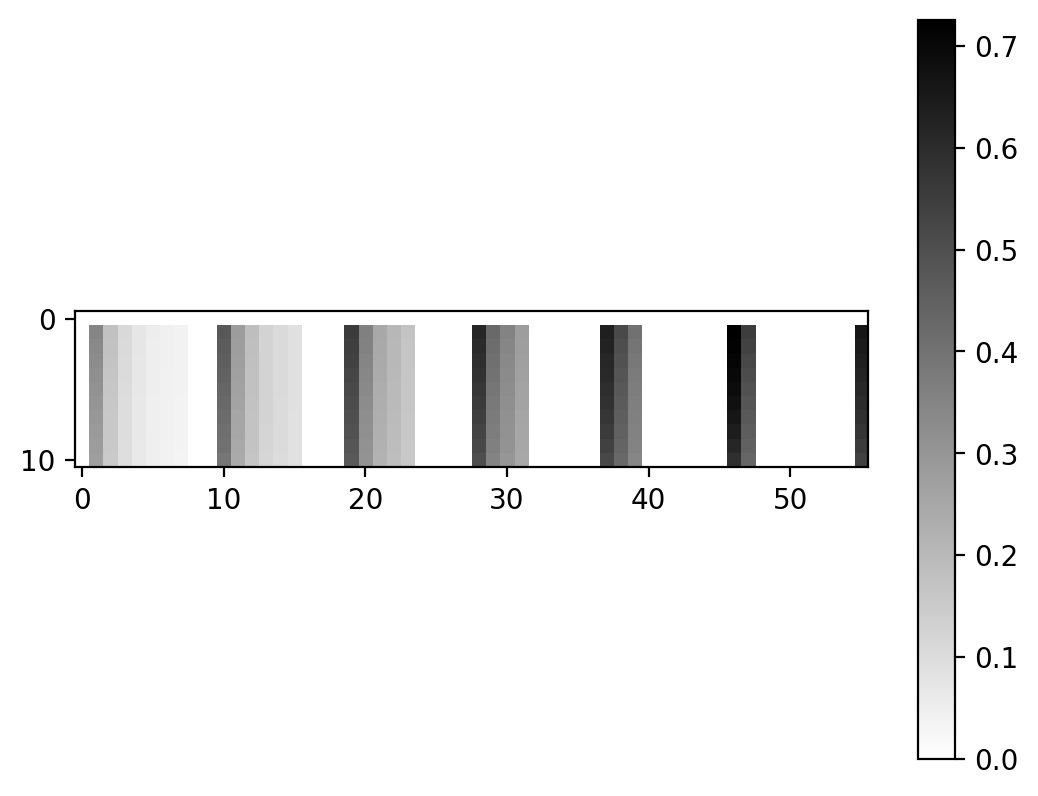

In [92]:
plt.imshow(concat_matrix, cmap='gray_r')
plt.colorbar()

In [93]:
examined_strengths = np.round(np.linspace(0, 1, 11), 1)
strength_values_num = len(examined_strengths)
num_layers = 8

every_layer_results = np.zeros((strength_values_num, num_layers))

# Test different strengths for layer 0
# The unsteered version corresponds to strength 0
results_inidividual_layer = {}
layer_tested = 0
print('layer tested: ', layer_tested)
for strength in examined_strengths:
    print('strength value: ', strength)
    for layer in range(0, len(model.encoder_layers)):
        strengths[layer] = strength
    print('strengths: ', strengths)

    model.eval()

    steered_states_all = {i: [] for i in range(len(model.encoder_layers))}
    pre_out_states_all = {i: [] for i in range(len(model.encoder_layers))}

    # nott melodies to jazz harmony
    for batch in nottValLoader:
        melodies = batch['pianoroll']
        harmony_ids = batch['harmony_ids']
        harmony_input, _ = full_to_partial_masking(
            harmony_ids,
            mask_token_id,
            0,
            bar_token_id=bar_token_id
        )
        valid_positions = harmony_input[ harmony_input != mask_token_id ]

        with torch.no_grad():
            logits, steered_states, pre_out = model(
                melodies.to(device),
                harmony_tokens=harmony_input.to(device),
                style_banks=jazz_train_states,
                steering_strengths=strengths,
                steer_mask=None,# valid_positions.to(device),
                get_layers_output=True,
            )
            for layer_idx, state in steered_states.items():
                steered_states_all[layer_idx].append(state.detach().cpu())
            for layer_idx, state in pre_out.items():
                pre_out_states_all[layer_idx].append(state.detach().cpu())
            # end for
        # end with
    # end batch
    results_inidividual_layer[strength] = {
        'steered': {i: torch.cat(chunks, dim=0) for i, chunks in steered_states_all.items() if chunks},
        'pre': {i: torch.cat(chunks, dim=0) for i, chunks in pre_out_states_all.items() if chunks}
    }

strength_idx = 0
for strength in np.round(np.linspace(0, 1, 11), 1):
    # Evaluate the post-intervention states.
    scores_post = latent_steering_progress(
        target_states=jazz_train_states,
        original_states=results_inidividual_layer[0]['steered'],
        generated_states=results_inidividual_layer[strength]['steered'],
    )

    # Evaluate the pre-intervention states.
    scores_pre = latent_steering_progress(
        target_states=jazz_train_states,
        original_states=results_inidividual_layer[0]['steered'],
        generated_states=results_inidividual_layer[strength]['pre'],
    )
    print('Strength in first layer', 10*'=')
    for layer in range(8):
        layer_scores = scores_pre[layer]
        print(f"Mean for layer {layer}:", layer_scores.mean())
        every_layer_results[strength_idx, layer] = layer_scores.mean()/strength
    strength_idx += 1

layer tested:  0
strength value:  0.0
strengths:  {1: 0.0, 0: 0.0, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.0, 7: 0.0}
strength value:  0.1
strengths:  {1: 0.1, 0: 0.1, 2: 0.1, 3: 0.1, 4: 0.1, 5: 0.1, 6: 0.1, 7: 0.1}
strength value:  0.2
strengths:  {1: 0.2, 0: 0.2, 2: 0.2, 3: 0.2, 4: 0.2, 5: 0.2, 6: 0.2, 7: 0.2}
strength value:  0.3
strengths:  {1: 0.3, 0: 0.3, 2: 0.3, 3: 0.3, 4: 0.3, 5: 0.3, 6: 0.3, 7: 0.3}
strength value:  0.4
strengths:  {1: 0.4, 0: 0.4, 2: 0.4, 3: 0.4, 4: 0.4, 5: 0.4, 6: 0.4, 7: 0.4}
strength value:  0.5
strengths:  {1: 0.5, 0: 0.5, 2: 0.5, 3: 0.5, 4: 0.5, 5: 0.5, 6: 0.5, 7: 0.5}
strength value:  0.6
strengths:  {1: 0.6, 0: 0.6, 2: 0.6, 3: 0.6, 4: 0.6, 5: 0.6, 6: 0.6, 7: 0.6}
strength value:  0.7
strengths:  {1: 0.7, 0: 0.7, 2: 0.7, 3: 0.7, 4: 0.7, 5: 0.7, 6: 0.7, 7: 0.7}
strength value:  0.8
strengths:  {1: 0.8, 0: 0.8, 2: 0.8, 3: 0.8, 4: 0.8, 5: 0.8, 6: 0.8, 7: 0.8}
strength value:  0.9
strengths:  {1: 0.9, 0: 0.9, 2: 0.9, 3: 0.9, 4: 0.9, 5: 0.9, 6: 0.9, 7: 0.9}
str

/tmp/ipykernel_1579170/4021290938.py:75: RuntimeWarning: invalid value encountered in scalar divide
  every_layer_results[strength_idx, layer] = layer_scores.mean()/strength


Strength in first layer ==========
Mean for layer 0: 0.0
Mean for layer 1: 0.034598283
Mean for layer 2: 0.05495306
Mean for layer 3: 0.075704716
Mean for layer 4: 0.09427693
Mean for layer 5: 0.106916465
Mean for layer 6: 0.13101389
Mean for layer 7: 0.1366879
Strength in first layer ==========
Mean for layer 0: 0.0
Mean for layer 1: 0.06717373
Mean for layer 2: 0.10529059
Mean for layer 3: 0.14254838
Mean for layer 4: 0.17413321
Mean for layer 5: 0.19649407
Mean for layer 6: 0.23944952
Mean for layer 7: 0.24398461
Strength in first layer ==========
Mean for layer 0: 0.0
Mean for layer 1: 0.098040864
Mean for layer 2: 0.1517976
Mean for layer 3: 0.2021012
Mean for layer 4: 0.24236359
Mean for layer 5: 0.27264488
Mean for layer 6: 0.33001962
Mean for layer 7: 0.32882646
Strength in first layer ==========
Mean for layer 0: 0.0
Mean for layer 1: 0.12734759
Mean for layer 2: 0.19464718
Mean for layer 3: 0.2553067
Mean for layer 4: 0.301344
Mean for layer 5: 0.33680773
Mean for layer 6: 0.

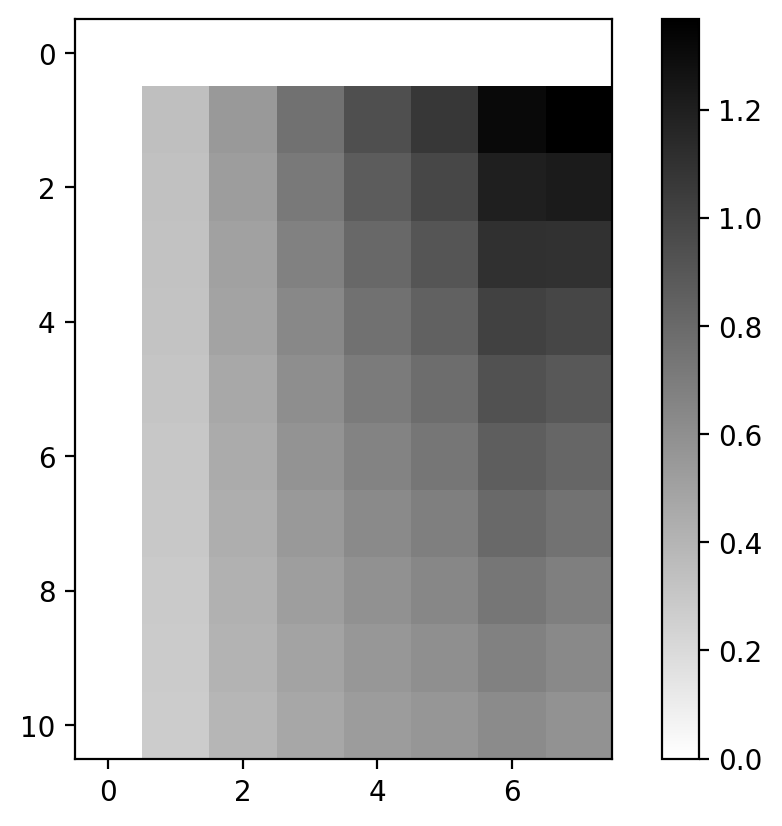

In [94]:
plt.imshow(every_layer_results, cmap='gray_r')
plt.colorbar()

In [95]:
print(np.max(concat_matrix), np.max(every_layer_results))

nan nan
